# 103_03 — Convergencia de las cadenas MCMC · Australia del Sur (SA1) 5 min · precio spot (asinh) · **barrido en $M$**

Paso **3a** del ciclo. Este notebook **sólo diagnostica las cadenas**: no
predice, no evalúa y no toca el bloque de prueba. Si algo aquí falla, los
números de `103_04` no significan nada, y por eso son notebooks separados.

Los cálculos viven en `fit/convergencia_barrido.py` y las figuras en
`graphics/viz_convergencia.py`; este notebook los orquesta.

Covariables cruzadas con un solo rezago ($p=M$): el diseño cambia con $M$, así que MATLAB entrena **cada** $M$ y `hyperparameters.json["trazas_en"]` apunta al propio punto. Datos reales: no hay generador contra el cual contrastar la selección (§6).

| Estadístico | Referencia | Lectura |
|---|---|---|
| ESS | Geyer (1992) | $\gtrsim 400$ ideal, $>100$ aceptable |
| Geweke $z$ | test $z$ entre segmentos | $\lvert z\rvert < 2$ ⇒ no se rechaza |
| $\hat R$ | Gelman-Rubin | $< 1.1$ ⇒ convergencia |

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, diagnosticar_punto, imprimir_convergencia,
    ocupacion_mezcla, diagnostico_gating, pip_punto,
    verificar_muestreador_predictor, diagnostico_paso_gamma,
    tabla_barrido, ocupacion_barrido, pip_barrido, veredicto_barrido,
)
from model_psbp_fd.graphics import (
    plot_global_components, plot_active_clusters,
    plot_convergence_bj, plot_convergence_pj,
    plot_ocupacion_mezcla, plot_gating, plot_diagnostico_vs_M,
    plot_ocupacion_vs_M, plot_pip_vs_M,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 103_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "sa1_103", 2   # ventana 2: entrena 2022-2024, prueba 2025 (103_01 §1.1)
M_FPCA_LIST = (10,)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la convergencia.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat
SD_PIP_MAX          = 0.15    # dispersión entre cadenas que se avisa
CORR_MIN_CONTRATO   = 0.999   # corr(inEout, predict) mínima, §7

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
# Salidas que CRUZAN los M: directorio hermano de los de cada punto.
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 80-83)")


EXPERIMENT_BASE : real_sa1_103_v02
barrido en M    : [10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_barrido_M   (archivos 80-83)


In [3]:
# EST[M] es el estado completo de cada punto; todo lo que sigue lo consume por índice.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST, PROJECT_ROOT,
                                  dominio=DOMINIO)

  M  comp  cadenas  covariables  seed_base
 10    10        1           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)


## 2. Lectura de las trazas

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)   # los M efectivamente disponibles

OK M=10: 10 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Tabla de diagnósticos

ESS, Geweke y $\hat R$ **sin generar figuras**. Una tabla por $M$, guardada en el
directorio de su punto (`40_diagnosticos_mcmc.csv`); la comparación entre $M$ va
en §8.

In [5]:
for M in M_OK:
    diag_df = diagnosticar_punto(EST[M])
    display(diag_df.style
        .format({"ess_min": "{:.1f}", "ess_mean": "{:.1f}",
                 "geweke_max": "{:+.2f}", "rhat": "{:.4f}"})
        .background_gradient(subset=["rhat"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption(f"M={M} - diagnósticos MCMC por componente FPCA y variable"))

imprimir_convergencia(EST, M_OK)

[tabla_diagnosticos] inicio (200 pasos)


  1/200 ( 0.5%) t=0.0s eta=0.4s  fpc_1 beta_j[fpc_1_lag1] rhat=nan ess_min=192


  10/200 ( 5.0%) t=0.0s eta=0.2s  fpc_1 beta_j[fpc_10_lag1] rhat=nan ess_min=1633


  20/200 (10.0%) t=0.0s eta=0.1s  fpc_1 p_j[fpc_10_lag1] rhat=nan ess_min=62


  30/200 (15.0%) t=0.0s eta=0.1s  fpc_2 beta_j[fpc_10_lag1] rhat=nan ess_min=1844


  40/200 (20.0%) t=0.0s eta=0.1s  fpc_2 p_j[fpc_10_lag1] rhat=nan ess_min=45


  50/200 (25.0%) t=0.0s eta=0.1s  fpc_3 beta_j[fpc_10_lag1] rhat=nan ess_min=1817


  60/200 (30.0%) t=0.0s eta=0.1s  fpc_3 p_j[fpc_10_lag1] rhat=nan ess_min=344


  70/200 (35.0%) t=0.1s eta=0.1s  fpc_4 beta_j[fpc_10_lag1] rhat=nan ess_min=1719


  80/200 (40.0%) t=0.1s eta=0.1s  fpc_4 p_j[fpc_10_lag1] rhat=nan ess_min=81


  90/200 (45.0%) t=0.1s eta=0.1s  fpc_5 beta_j[fpc_10_lag1] rhat=nan ess_min=1975


  100/200 (50.0%) t=0.1s eta=0.1s  fpc_5 p_j[fpc_10_lag1] rhat=nan ess_min=108


  110/200 (55.0%) t=0.1s eta=0.1s  fpc_6 beta_j[fpc_10_lag1] rhat=nan ess_min=1677


  120/200 (60.0%) t=0.1s eta=0.1s  fpc_6 p_j[fpc_10_lag1] rhat=nan ess_min=194


  130/200 (65.0%) t=0.1s eta=0.1s  fpc_7 beta_j[fpc_10_lag1] rhat=nan ess_min=1861


  140/200 (70.0%) t=0.1s eta=0.0s  fpc_7 p_j[fpc_10_lag1] rhat=nan ess_min=182


  150/200 (75.0%) t=0.1s eta=0.0s  fpc_8 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  160/200 (80.0%) t=0.1s eta=0.0s  fpc_8 p_j[fpc_10_lag1] rhat=nan ess_min=297


  170/200 (85.0%) t=0.1s eta=0.0s  fpc_9 beta_j[fpc_10_lag1] rhat=nan ess_min=1381


  180/200 (90.0%) t=0.1s eta=0.0s  fpc_9 p_j[fpc_10_lag1] rhat=nan ess_min=64


  190/200 (95.0%) t=0.1s eta=0.0s  fpc_10 beta_j[fpc_10_lag1] rhat=nan ess_min=1737


  200/200 (100.0%) t=0.1s eta=0.0s  fpc_10 p_j[fpc_10_lag1] rhat=nan ess_min=64


[tabla_diagnosticos] listo: 200 pasos en 0.2s  76 variables sin converger de 200


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\fit\diagnostics_mcmc.py:269: RuntimeWarning: All-NaN axis encountered
  "rhat_max":        float(np.nanmax(tabla["rhat"])),


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,1,2000,191.8,191.8,+3.41,nan,False
1,1,beta_j,fpc_2_lag1,1,2000,1565.4,1565.4,+1.61,nan,True
2,1,beta_j,fpc_3_lag1,1,2000,1438.9,1438.9,+2.52,nan,False
3,1,beta_j,fpc_4_lag1,1,2000,778.4,778.4,+3.55,nan,False
4,1,beta_j,fpc_5_lag1,1,2000,1696.5,1696.5,+0.58,nan,True
5,1,beta_j,fpc_6_lag1,1,2000,2000.0,2000.0,+0.07,nan,True
6,1,beta_j,fpc_7_lag1,1,2000,1786.6,1786.6,+0.16,nan,True
7,1,beta_j,fpc_8_lag1,1,2000,2000.0,2000.0,+1.07,nan,True
8,1,beta_j,fpc_9_lag1,1,2000,2000.0,2000.0,+0.92,nan,True
9,1,beta_j,fpc_10_lag1,1,2000,1633.3,1633.3,+2.15,nan,False


  M = 10   (real_sa1_103_v02_m10)
  Rhat max nan (umbral 1.1)  ·  ESS min 9.2 (umbral 100.0)  ·  |Geweke| max 12.32 (umbral 2.0)
  variables sin converger: 76 de 200   VEREDICTO: X REVISAR
    · FPC 1 beta_j fpc_1_lag1: Rhat=nan ESS=192 G=+3.41
    · FPC 1 beta_j fpc_3_lag1: Rhat=nan ESS=1439 G=+2.52
    · FPC 1 beta_j fpc_4_lag1: Rhat=nan ESS=778 G=+3.55
    · FPC 1 beta_j fpc_10_lag1: Rhat=nan ESS=1633 G=+2.15
    · FPC 1 p_j fpc_3_lag1: Rhat=nan ESS=92 G=+1.53
    · FPC 1 p_j fpc_4_lag1: Rhat=nan ESS=153 G=+3.44
    · FPC 1 p_j fpc_6_lag1: Rhat=nan ESS=15 G=+1.35
    · FPC 1 p_j fpc_7_lag1: Rhat=nan ESS=32 G=+1.28
    · FPC 1 p_j fpc_10_lag1: Rhat=nan ESS=62 G=+1.86
    · FPC 2 beta_j fpc_5_lag1: Rhat=nan ESS=254 G=+3.49
    · FPC 2 beta_j fpc_9_lag1: Rhat=nan ESS=1336 G=+2.03
    · FPC 2 p_j fpc_1_lag1: Rhat=nan ESS=48 G=+2.01
    · FPC 2 p_j fpc_2_lag1: Rhat=nan ESS=152 G=+2.22
    · FPC 2 p_j fpc_3_lag1: Rhat=nan ESS=47 G=+2.41
    · FPC 2 p_j fpc_4_lag1: Rhat=nan ESS=70 G=+0.16


## 4. Ocupación de la mezcla

`N1out` es $\max_i S_i$: cuántos átomos están efectivamente ocupados en cada
iteración. Decide si el truncamiento en $N$ átomos es suficiente y suele ser
**lo último en mezclar**, de modo que conviene mirarlo antes de fijar el `burn`.
Si la traza se pega contra $N$, el truncamiento está mordiendo y hay que subirlo.

! [M=10] alguna cadena alcanza N: subir mcmc_config['N'].


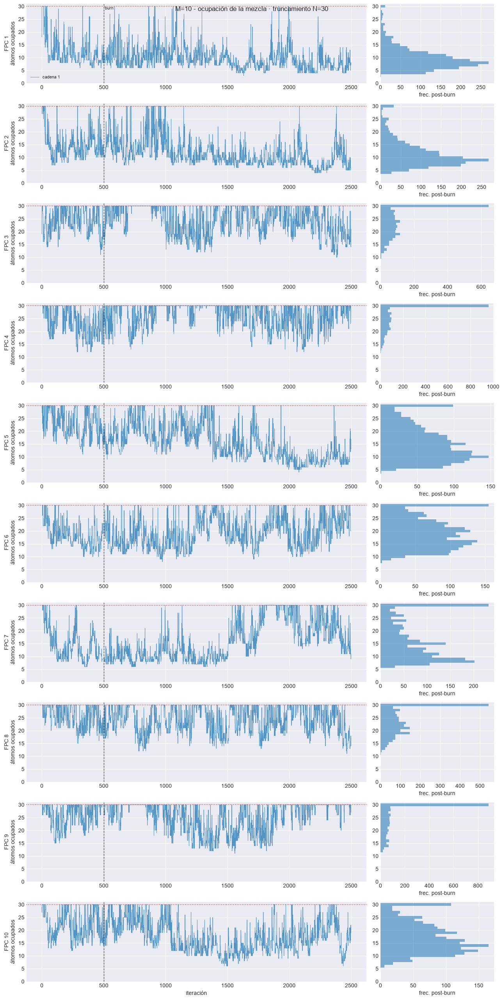

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,10,1,1,9.65,30,27.0,30,True,0.60%
1,10,2,1,11.40,30,30.0,30,True,1.65%
2,10,3,1,24.27,30,30.0,30,True,32.20%
3,10,4,1,26.35,30,30.0,30,True,47.95%
4,10,5,1,15.29,30,30.0,30,True,4.95%
5,10,6,1,19.32,30,30.0,30,True,7.75%
6,10,7,1,16.12,30,30.0,30,True,11.60%
7,10,8,1,24.00,30,30.0,30,True,27.15%
8,10,9,1,25.35,30,30.0,30,True,44.35%
9,10,10,1,17.14,30,30.0,30,True,5.40%


In [6]:
for M in M_OK:
    e = EST[M]
    ocup_df = ocupacion_mezcla(e, M)
    plot_ocupacion_mezcla(e, M, e["paths"]["out_report"] / "41_ocupacion_mezcla.png")
    plt.show()
    display(ocup_df.style.format({"media": "{:.2f}", "p99": "{:.1f}", "frac_en_N": "{:.2%}"})
            .set_caption(f"M={M} - átomos ocupados post-calentamiento"))

### 4.1 Gating: $\psi$, $\alpha$, $\Gamma$

Promedios ponderados por el peso medio de cada átomo, $\bar w_h=\frac1n\sum_i\pi_h(x_i)$,
para que no dependan del etiquetado. **Señal de gating** = átomos efectivos
globales menos por punto (≈ 0 si los pesos son los mismos en todo $x$);
**sd del argumento** = dispersión en $i$ de $\alpha_h-\sum_j\psi_{hj}|x_{ij}-\Gamma_{hj}|$.

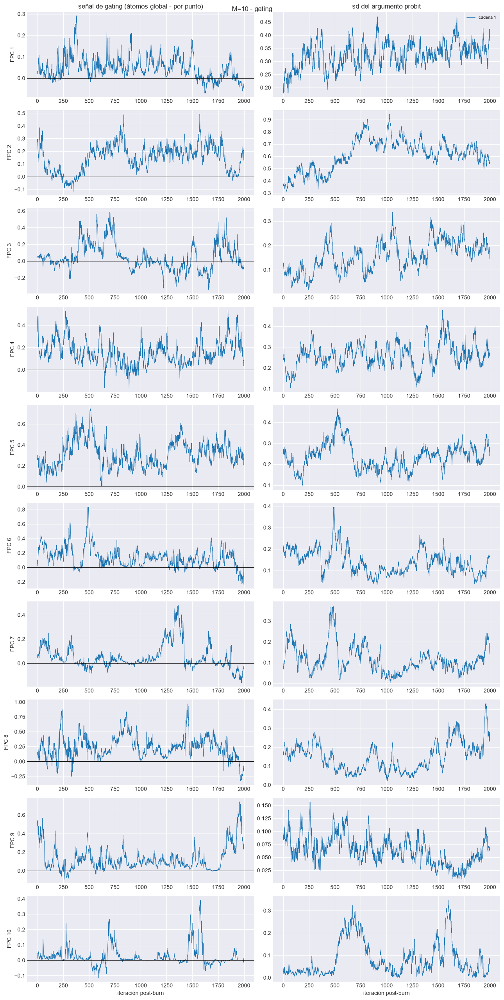

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,10,1,atomos_global,2.099,1,2000,4,4,11.340,nan,False
1,10,1,atomos_punto,2.049,1,2000,4,4,9.285,nan,False
2,10,1,senal_gating,0.050,1,2000,22,22,0.319,nan,False
3,10,1,sd_argumento,0.324,1,2000,27,27,5.801,nan,False
4,10,1,alpha,1.801,1,2000,4,4,8.341,nan,False
5,10,1,psi_0,0.402,1,2000,14,14,0.315,nan,False
6,10,1,psi_1,0.234,1,2000,48,48,0.002,nan,False
7,10,1,psi_2,0.589,1,2000,7,7,3.695,nan,False
8,10,1,psi_3,0.259,1,2000,9,9,2.561,nan,False
9,10,1,psi_4,1.101,1,2000,39,39,1.433,nan,False


In [7]:
_CACHE_GATING = {}      # clave (M, componente, cadena): las series cuestan

for M in M_OK:
    e = EST[M]
    gat, series = diagnostico_gating(e, M, _CACHE_GATING)
    plot_gating(series, e, M, e["paths"]["out_report"] / "49_gating.png")
    plt.show()
    display(gat.style.format({c: "{:.3f}" for c in gat.columns
                              if c.startswith("media_") or c in ("rhat", "geweke_max")}
                             | {"ess_min": "{:.0f}", "ess_mean": "{:.0f}"})
            .set_caption(f"M={M} - gating post-calentamiento"))

## 5. Figuras de convergencia por parámetro

== M=10 ==============================================


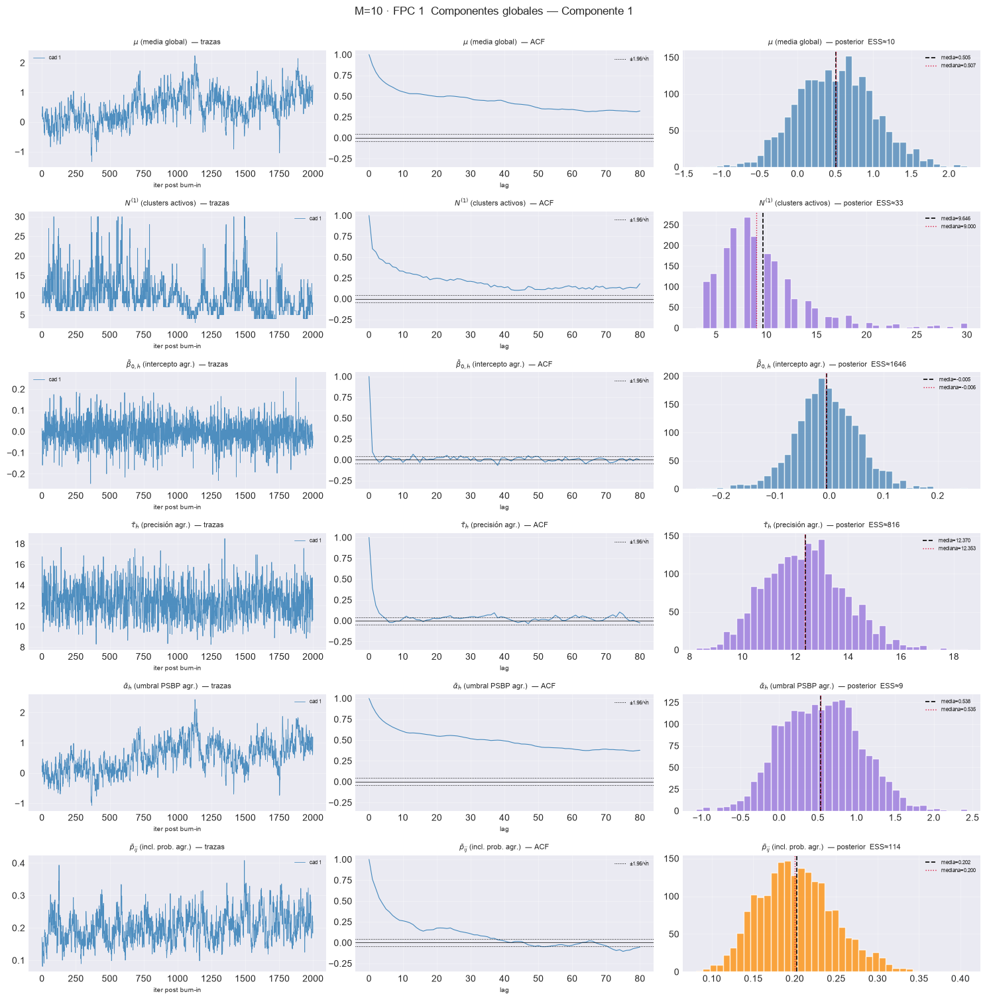

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:276: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:278: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


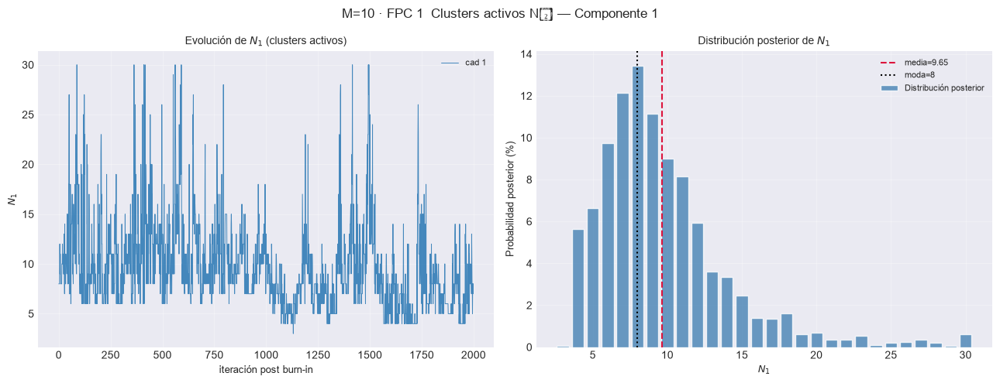

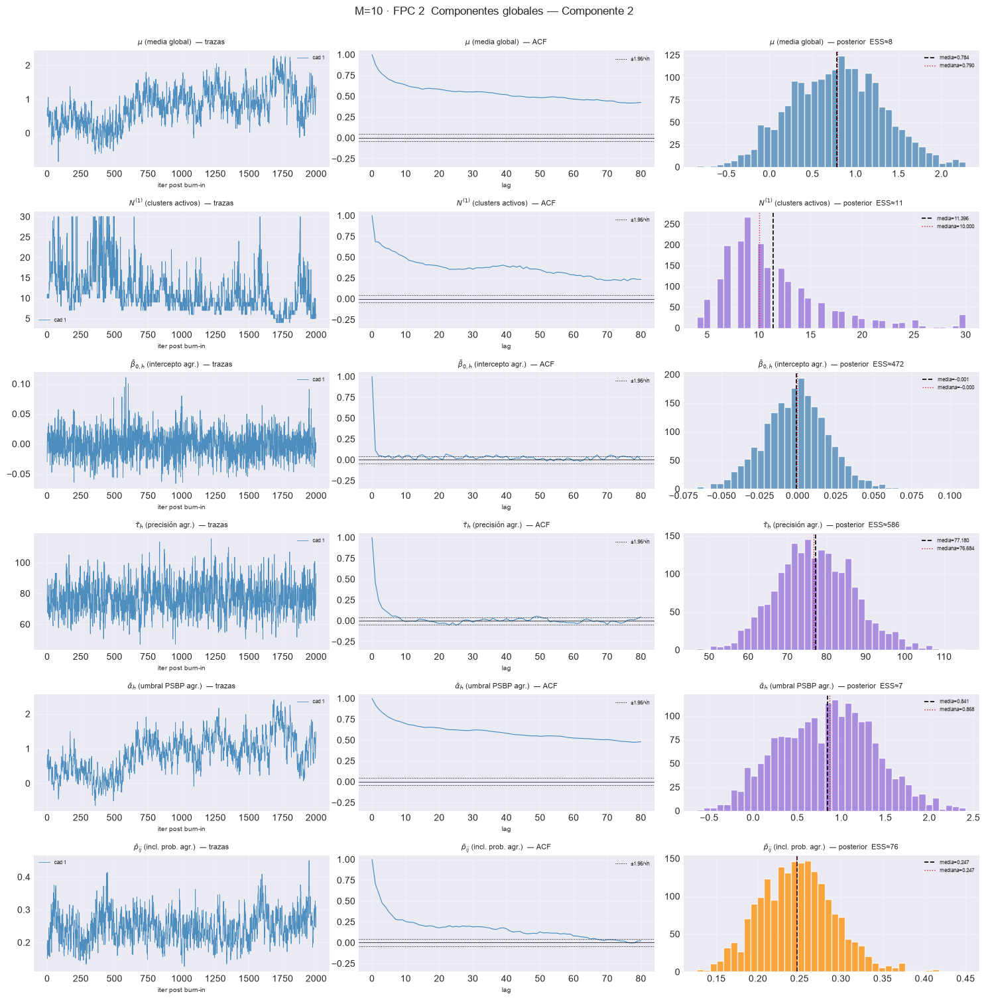

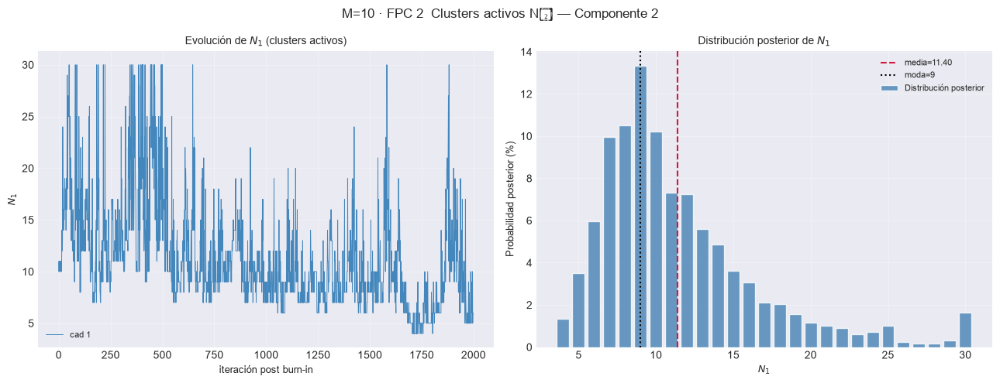

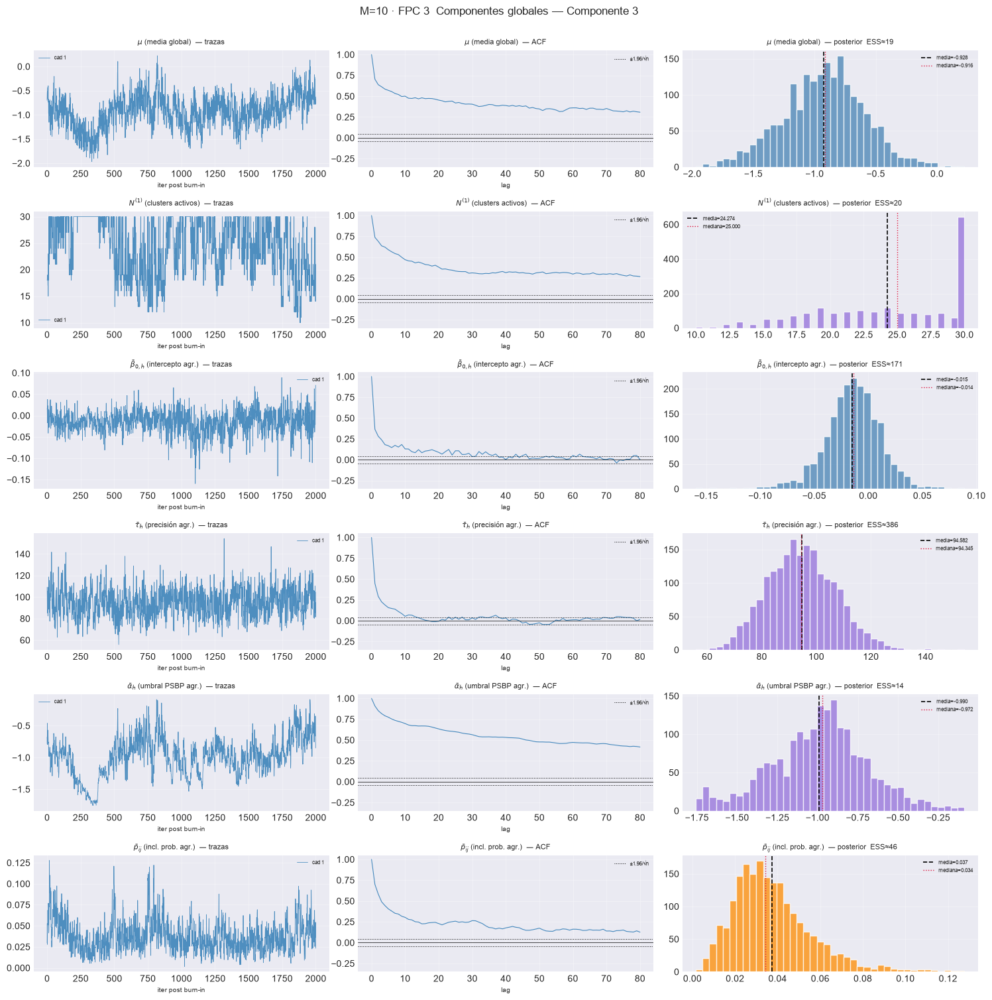

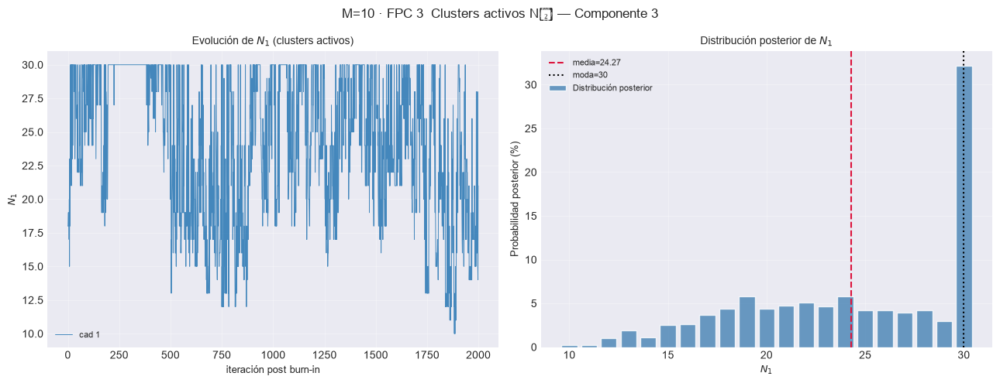

...

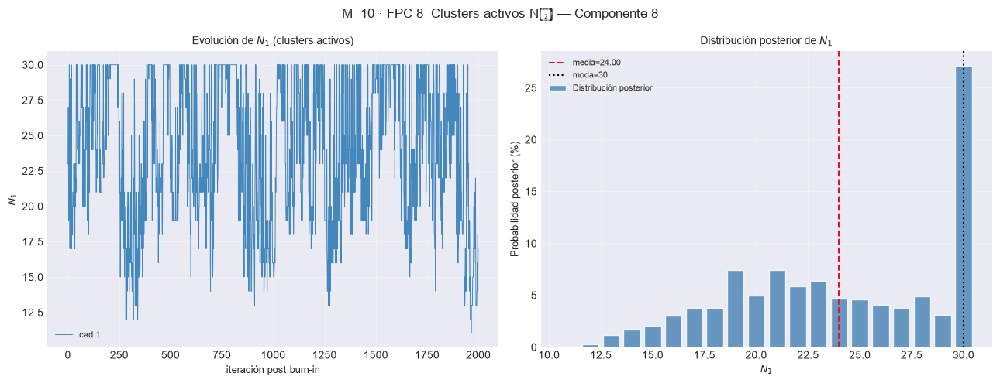

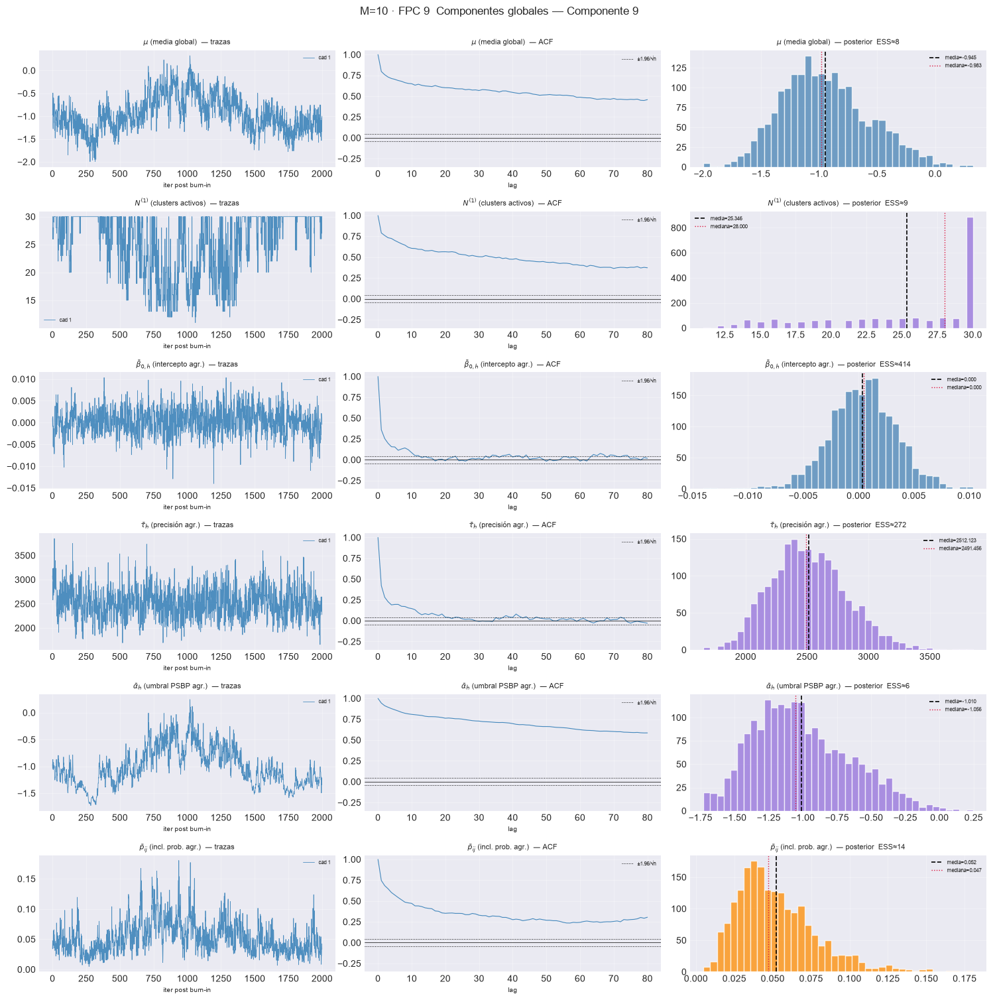

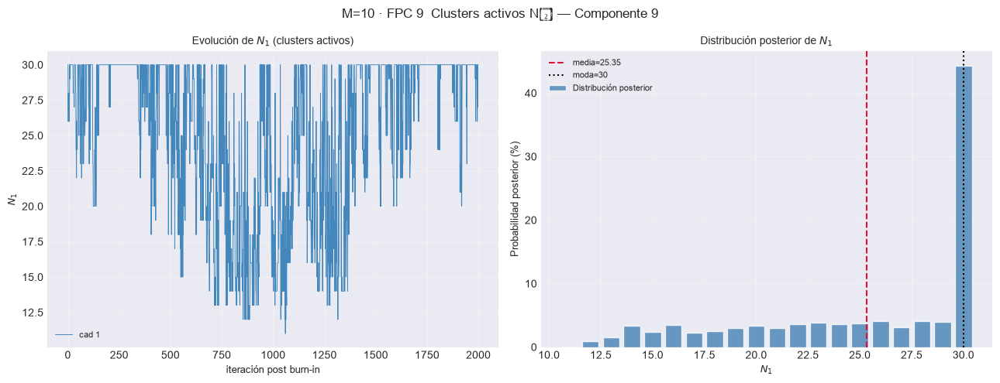

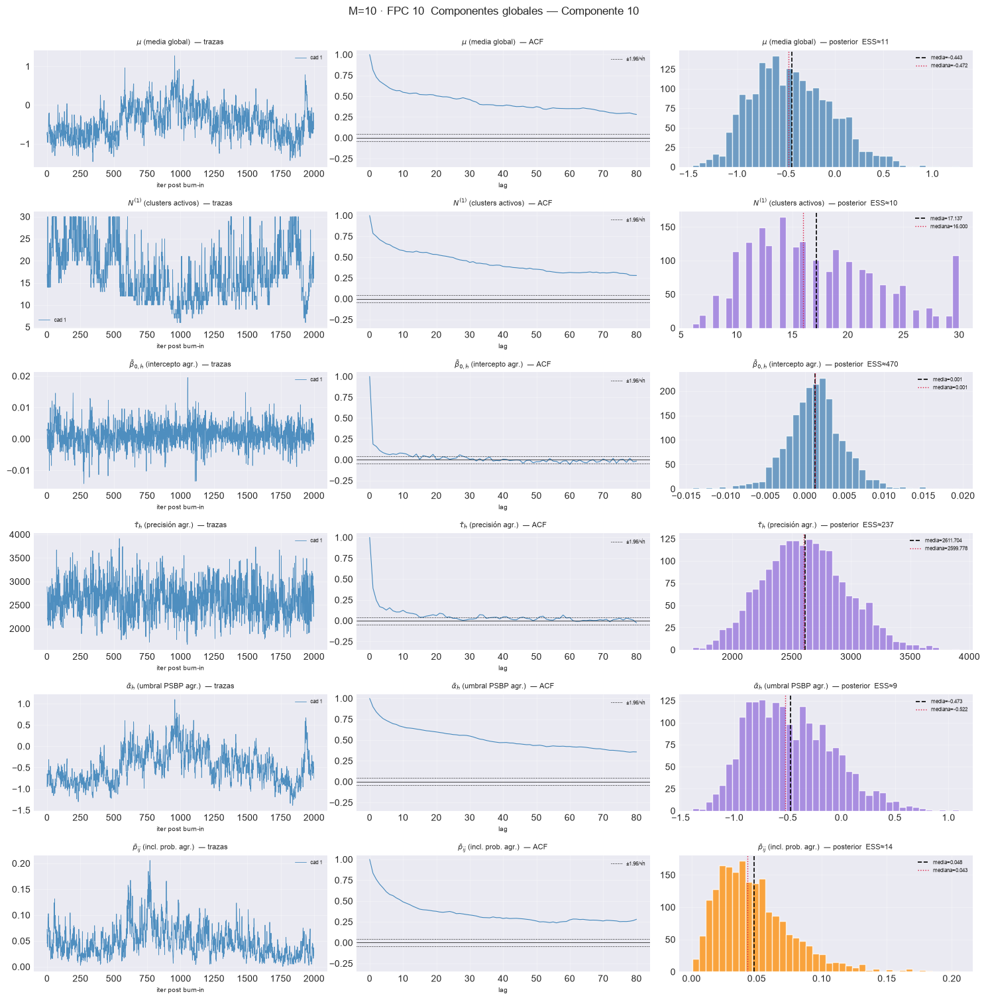

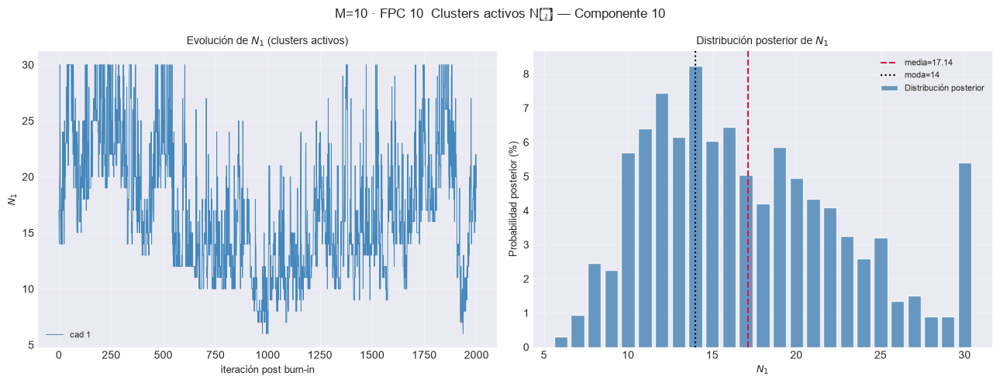

In [8]:
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc = e["component_idx"][k] + 1
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_global_components(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"42_global_k{fpc}.png"))
        plt.show()
        plot_active_clusters(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"43_clusters_k{fpc}.png"))
        plt.show()

== M=10 ==============================================
[plot_convergence_bj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=192  |G|=3.41  ✗


  2/10 (20.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1565  |G|=1.61  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=1439  |G|=2.52  ✗

  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=778  |G|=3.55  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1696  |G|=0.58  ✓


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.07  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1787  |G|=0.16  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=1.07  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.92  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1633  |G|=2.15  ✗

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 1]] listo: 10 pasos en 4.3s  4/10 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


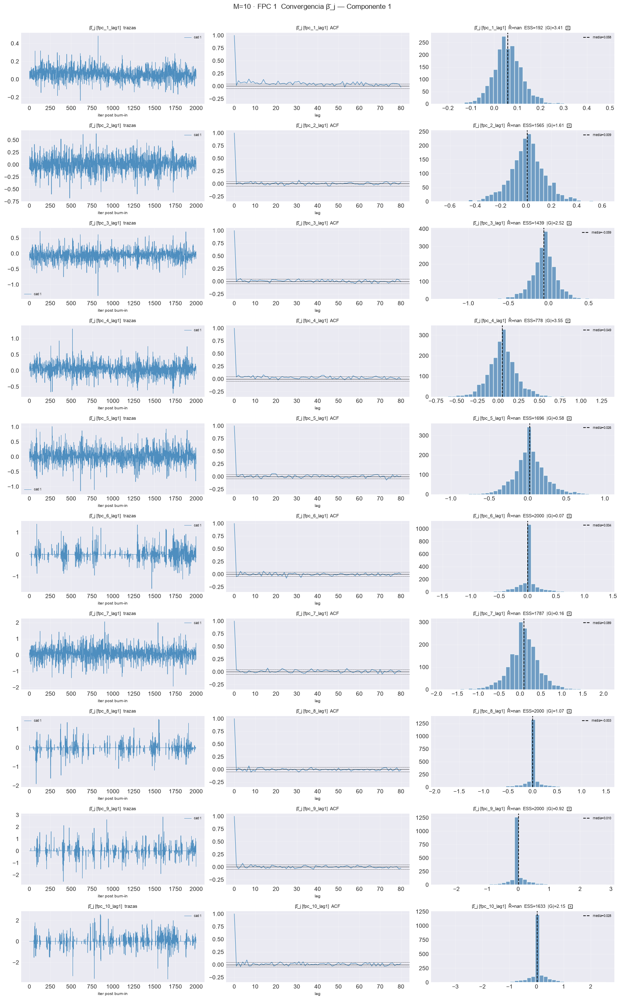

[plot_convergence_pj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.3s  fpc_1_lag1  rhat=nan  ess_min=165  |G|=0.62  ✓


  2/10 (20.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=270  |G|=0.64  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=92  |G|=1.53  ✗


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=153  |G|=3.44  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=104  |G|=0.54  ✓


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=15  |G|=1.35  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=32  |G|=1.28  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=104  |G|=0.89  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=124  |G|=1.44  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=62  |G|=1.86  ✗


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 10 pasos en 3.4s  5/10 sin converger


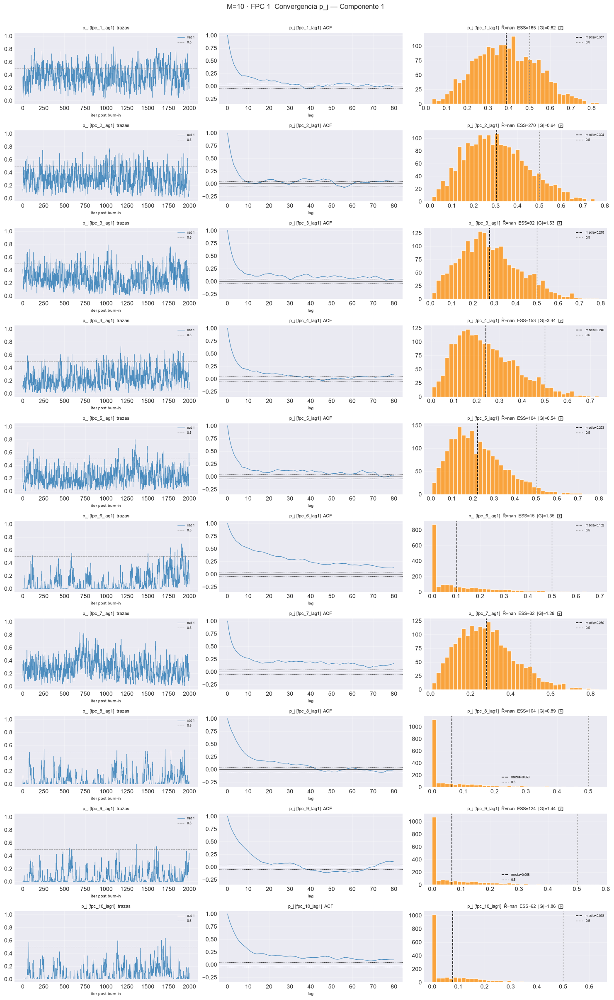

[plot_convergence_bj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1641  |G|=0.93  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=940  |G|=0.36  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=1220  |G|=1.46  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.89  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=254  |G|=3.49  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=167  |G|=1.38  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1023  |G|=0.29  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.85  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1336  |G|=2.03  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1844  |G|=0.66  ✓


[plot_convergence_bj[FPC 2]] listo: 10 pasos en 3.8s  2/10 sin converger


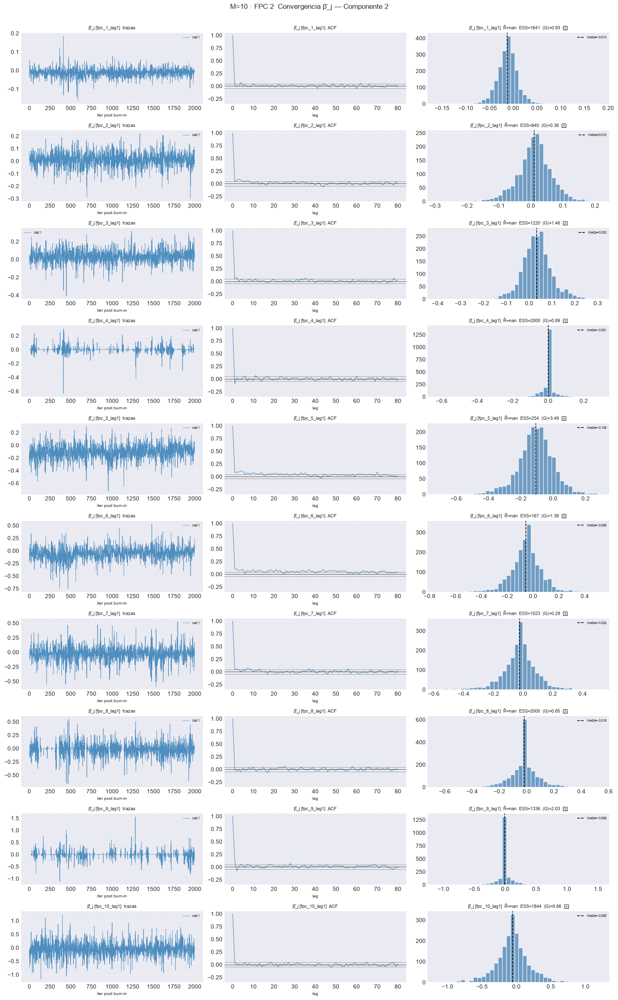

[plot_convergence_pj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=48  |G|=2.01  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=152  |G|=2.22  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=47  |G|=2.41  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=70  |G|=0.16  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=75  |G|=5.11  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=97  |G|=0.45  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=221  |G|=0.17  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=48  |G|=1.59  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=73  |G|=0.05  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=45  |G|=4.35  ✗


[plot_convergence_pj[FPC 2]] listo: 10 pasos en 4.8s  9/10 sin converger


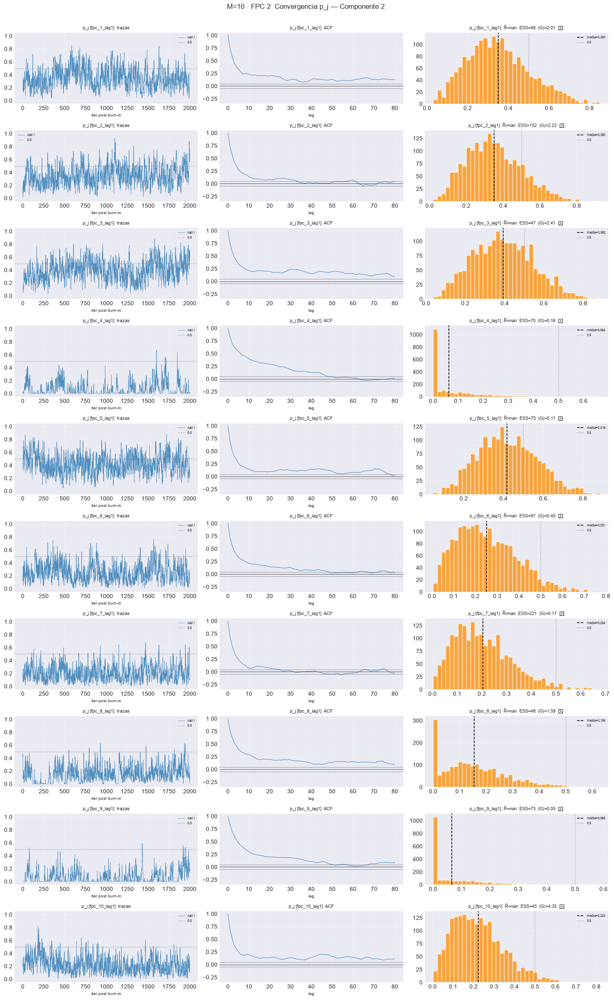

[plot_convergence_bj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1068  |G|=1.69  ✓


  2/10 (20.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1562  |G|=0.46  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=119  |G|=2.48  ✗


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=1039  |G|=0.29  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.36  ✓


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1337  |G|=0.63  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=174  |G|=3.19  ✗

  8/10 (80.0%) t=0.2s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.81  ✓

  9/10 (90.0%) t=0.3s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=40  |G|=1.08  ✗


  10/10 (100.0%) t=0.7s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1817  |G|=0.59  ✓


[plot_convergence_bj[FPC 3]] listo: 10 pasos en 5.3s  3/10 sin converger


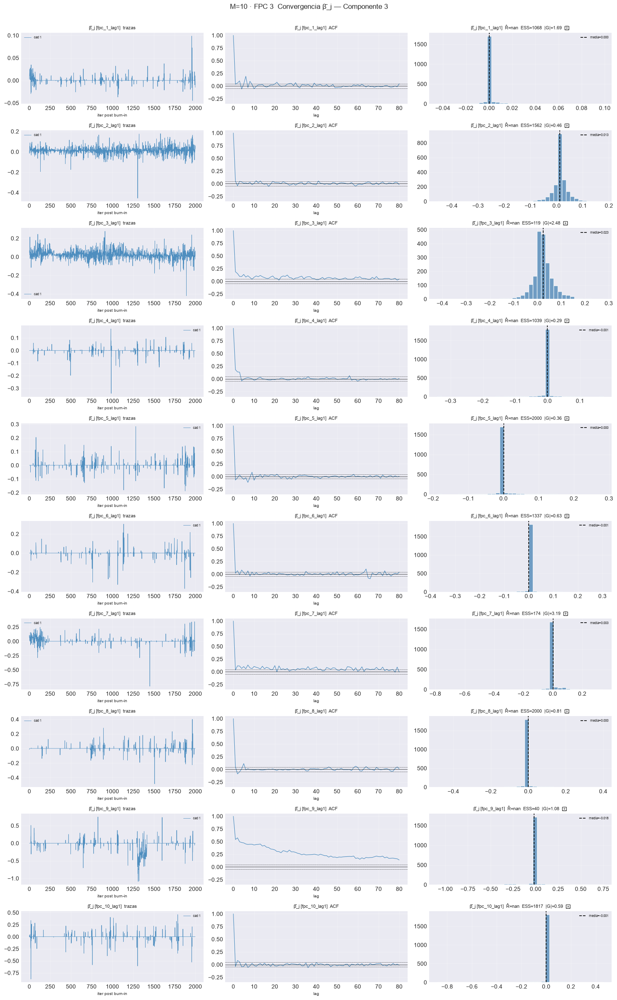

[plot_convergence_pj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.1s eta=0.5s  fpc_1_lag1  rhat=nan  ess_min=91  |G|=1.20  ✗


  2/10 (20.0%) t=0.1s eta=0.4s  fpc_2_lag1  rhat=nan  ess_min=279  |G|=0.58  ✓


  3/10 (30.0%) t=0.3s eta=0.6s  fpc_3_lag1  rhat=nan  ess_min=30  |G|=6.57  ✗

  4/10 (40.0%) t=0.4s eta=0.6s  fpc_4_lag1  rhat=nan  ess_min=241  |G|=0.02  ✓


  5/10 (50.0%) t=0.5s eta=0.5s  fpc_5_lag1  rhat=nan  ess_min=194  |G|=0.44  ✓


  6/10 (60.0%) t=0.6s eta=0.4s  fpc_6_lag1  rhat=nan  ess_min=335  |G|=1.56  ✓


  7/10 (70.0%) t=0.6s eta=0.3s  fpc_7_lag1  rhat=nan  ess_min=28  |G|=4.22  ✗

  8/10 (80.0%) t=0.7s eta=0.2s  fpc_8_lag1  rhat=nan  ess_min=265  |G|=1.14  ✓


  9/10 (90.0%) t=0.8s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=63  |G|=0.13  ✗


  10/10 (100.0%) t=0.8s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=344  |G|=0.76  ✓


[plot_convergence_pj[FPC 3]] listo: 10 pasos en 6.9s  4/10 sin converger


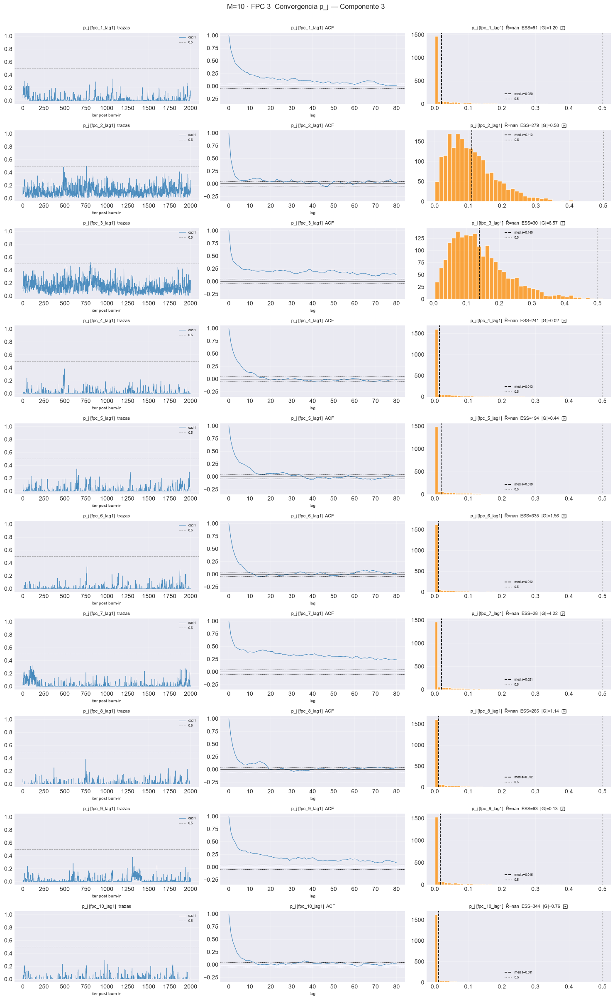

[plot_convergence_bj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.1s eta=0.5s  fpc_1_lag1  rhat=nan  ess_min=1775  |G|=0.72  ✓


  2/10 (20.0%) t=0.1s eta=0.5s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=1.37  ✓


  3/10 (30.0%) t=0.2s eta=0.5s  fpc_3_lag1  rhat=nan  ess_min=975  |G|=0.24  ✓


  4/10 (40.0%) t=0.2s eta=0.4s  fpc_4_lag1  rhat=nan  ess_min=255  |G|=3.69  ✗


  5/10 (50.0%) t=0.3s eta=0.3s  fpc_5_lag1  rhat=nan  ess_min=653  |G|=0.84  ✓


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=1533  |G|=3.30  ✗

  7/10 (70.0%) t=0.4s eta=0.2s  fpc_7_lag1  rhat=nan  ess_min=953  |G|=0.64  ✓


  8/10 (80.0%) t=0.4s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=1466  |G|=3.29  ✗

  9/10 (90.0%) t=0.4s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.27  ✓


  10/10 (100.0%) t=0.8s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1719  |G|=0.65  ✓


[plot_convergence_bj[FPC 4]] listo: 10 pasos en 6.4s  3/10 sin converger


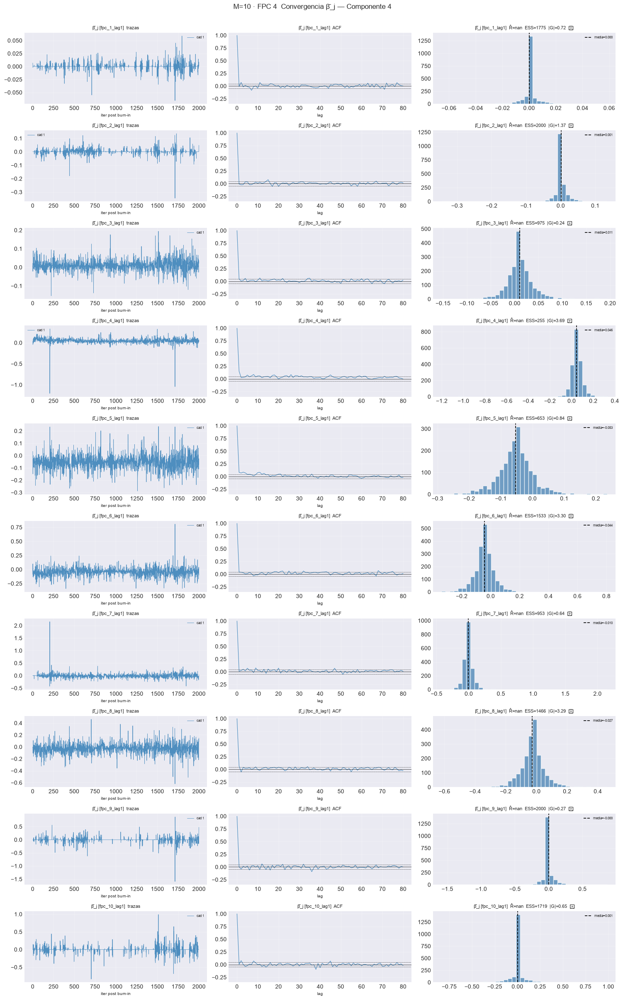

[plot_convergence_pj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.3s  fpc_1_lag1  rhat=nan  ess_min=144  |G|=0.97  ✓


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=57  |G|=0.61  ✗


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=22  |G|=0.52  ✗


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=24  |G|=5.87  ✗


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=53  |G|=0.70  ✗


  6/10 (60.0%) t=0.2s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=33  |G|=1.64  ✗


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=98  |G|=1.11  ✗


  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=138  |G|=0.92  ✓


  9/10 (90.0%) t=0.3s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=71  |G|=0.32  ✗


  10/10 (100.0%) t=0.4s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=81  |G|=1.19  ✗


[plot_convergence_pj[FPC 4]] listo: 10 pasos en 5.8s  8/10 sin converger


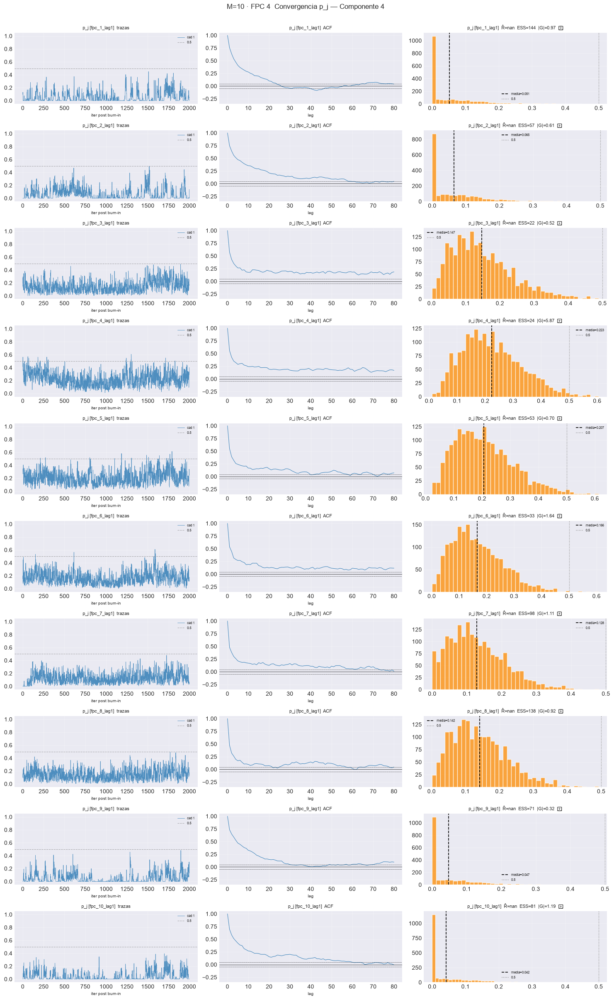

[plot_convergence_bj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.4s  fpc_1_lag1  rhat=nan  ess_min=371  |G|=1.11  ✓


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=4.81  ✗


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=1.85  ✓


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.65  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=343  |G|=1.09  ✓


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.17  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.44  ✓


  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=1443  |G|=1.01  ✓


  9/10 (90.0%) t=0.7s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=1003  |G|=0.86  ✓


  10/10 (100.0%) t=0.8s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1975  |G|=0.48  ✓


[plot_convergence_bj[FPC 5]] listo: 10 pasos en 5.8s  1/10 sin converger


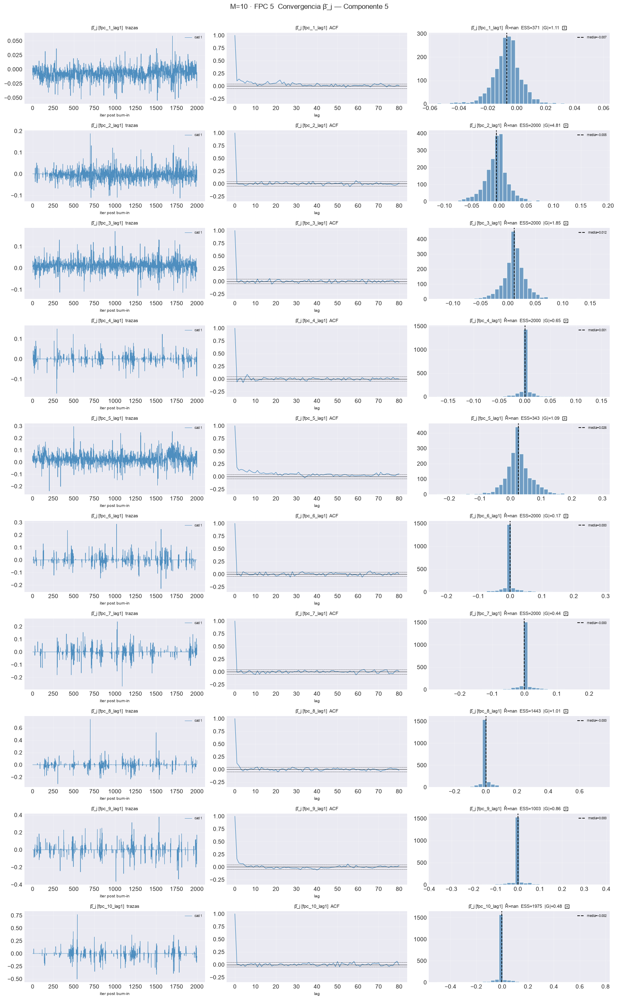

[plot_convergence_pj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.3s  fpc_1_lag1  rhat=nan  ess_min=140  |G|=1.11  ✓


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=16  |G|=12.32  ✗


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=323  |G|=0.39  ✓


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=101  |G|=0.17  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=151  |G|=2.78  ✗


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=79  |G|=2.01  ✗


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=112  |G|=1.58  ✓


  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=76  |G|=0.22  ✗


  9/10 (90.0%) t=0.4s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=155  |G|=1.51  ✓


  10/10 (100.0%) t=0.4s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=108  |G|=1.55  ✓


[plot_convergence_pj[FPC 5]] listo: 10 pasos en 5.2s  4/10 sin converger


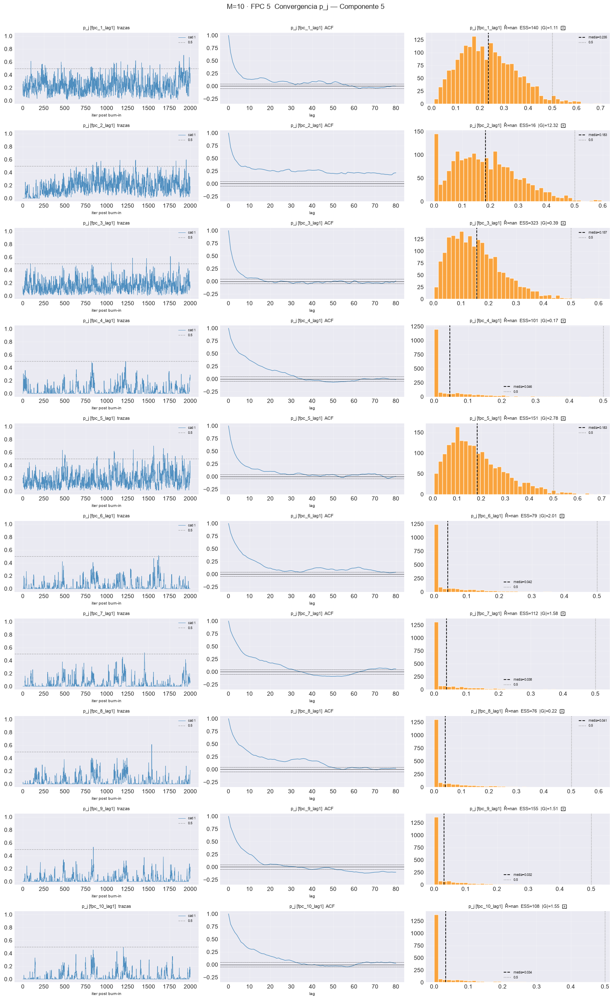

[plot_convergence_bj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1216  |G|=1.05  ✓


  2/10 (20.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=0.17  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=1066  |G|=1.31  ✓


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.49  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=29  |G|=1.79  ✗


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=395  |G|=0.03  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1327  |G|=0.02  ✓


  8/10 (80.0%) t=0.2s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=1407  |G|=1.10  ✓


  9/10 (90.0%) t=0.6s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=1404  |G|=1.28  ✓


  10/10 (100.0%) t=0.6s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1677  |G|=0.08  ✓


[plot_convergence_bj[FPC 6]] listo: 10 pasos en 4.4s  1/10 sin converger


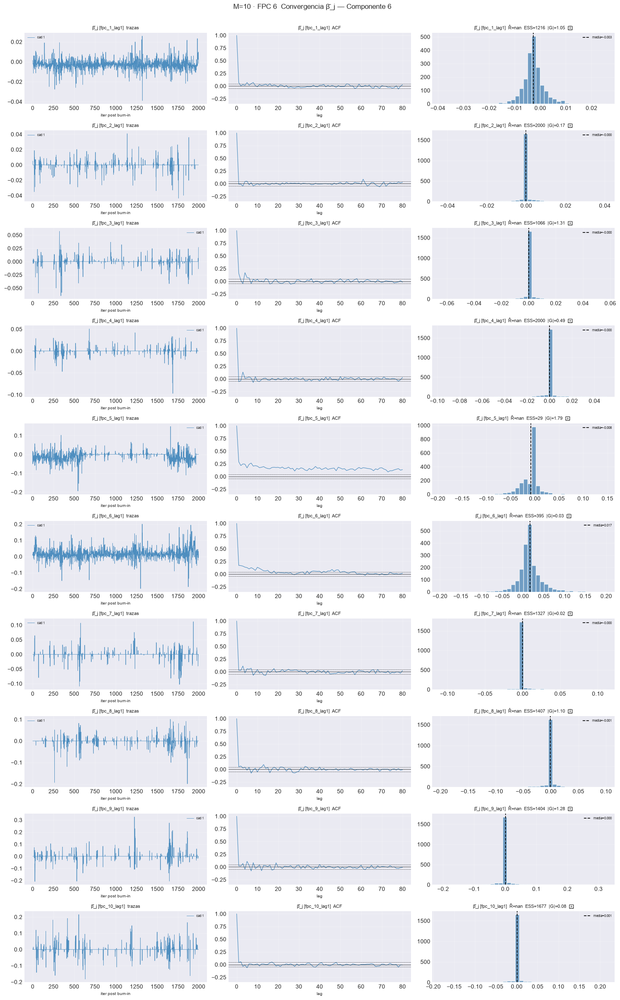

[plot_convergence_pj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.4s  fpc_1_lag1  rhat=nan  ess_min=41  |G|=1.15  ✗


  2/10 (20.0%) t=0.1s eta=0.4s  fpc_2_lag1  rhat=nan  ess_min=235  |G|=0.95  ✓


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=179  |G|=0.04  ✓


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=178  |G|=0.63  ✓


  5/10 (50.0%) t=0.3s eta=0.3s  fpc_5_lag1  rhat=nan  ess_min=12  |G|=2.91  ✗


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=278  |G|=0.74  ✓


  7/10 (70.0%) t=0.4s eta=0.2s  fpc_7_lag1  rhat=nan  ess_min=143  |G|=1.39  ✓


  8/10 (80.0%) t=0.4s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=115  |G|=1.21  ✓


  9/10 (90.0%) t=0.5s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=135  |G|=0.58  ✓

  10/10 (100.0%) t=0.5s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=194  |G|=0.24  ✓


[plot_convergence_pj[FPC 6]] listo: 10 pasos en 7.1s  2/10 sin converger


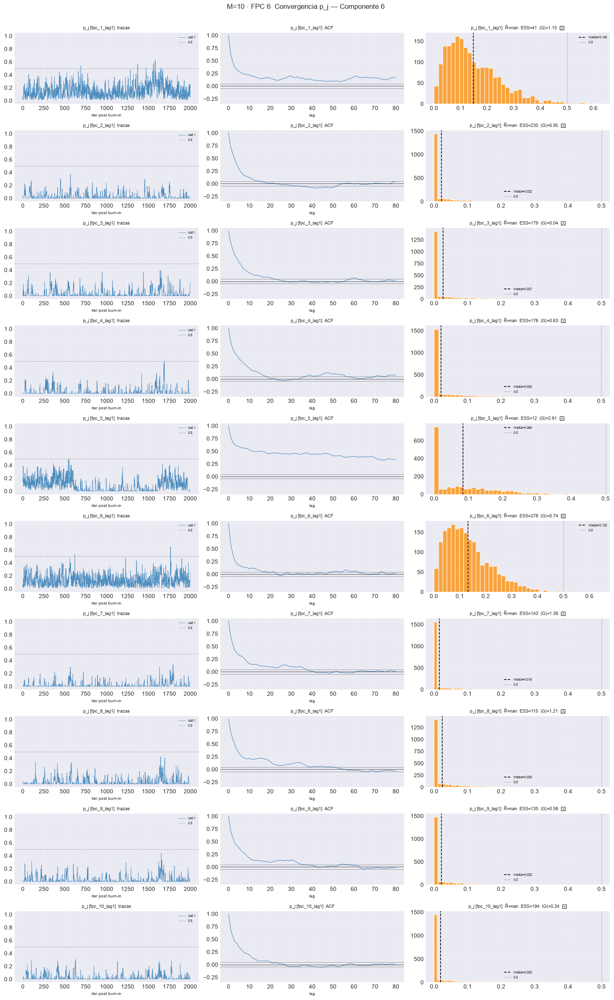

[plot_convergence_bj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.3s  fpc_1_lag1  rhat=nan  ess_min=1273  |G|=3.06  ✗


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=1.29  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=1816  |G|=3.64  ✗


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=1103  |G|=0.89  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=1593  |G|=0.47  ✓


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1714  |G|=1.14  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=145  |G|=1.26  ✓


  8/10 (80.0%) t=0.7s eta=0.2s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.19  ✓


  9/10 (90.0%) t=0.7s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=687  |G|=0.57  ✓


  10/10 (100.0%) t=0.7s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1861  |G|=0.11  ✓


[plot_convergence_bj[FPC 7]] listo: 10 pasos en 5.8s  2/10 sin converger


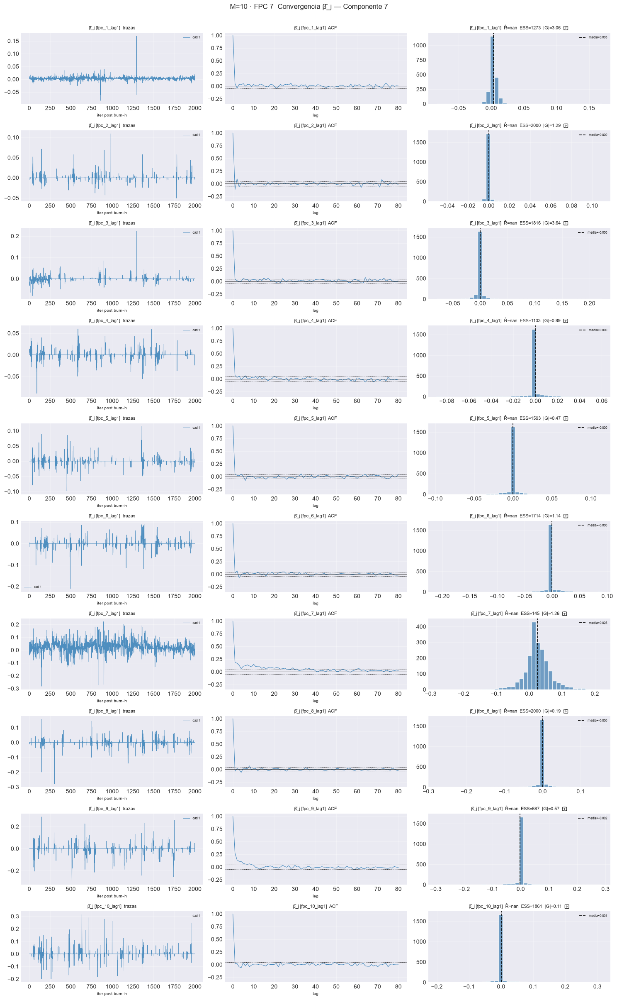

[plot_convergence_pj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.4s  fpc_1_lag1  rhat=nan  ess_min=25  |G|=2.95  ✗


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=235  |G|=2.36  ✗


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=19  |G|=9.57  ✗


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=140  |G|=1.76  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=179  |G|=2.05  ✗


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=129  |G|=0.65  ✓


  7/10 (70.0%) t=0.4s eta=0.2s  fpc_7_lag1  rhat=nan  ess_min=25  |G|=3.81  ✗


  8/10 (80.0%) t=0.4s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=277  |G|=0.24  ✓


  9/10 (90.0%) t=0.4s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=180  |G|=1.43  ✓


  10/10 (100.0%) t=0.5s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=182  |G|=1.51  ✓


[plot_convergence_pj[FPC 7]] listo: 10 pasos en 6.9s  5/10 sin converger


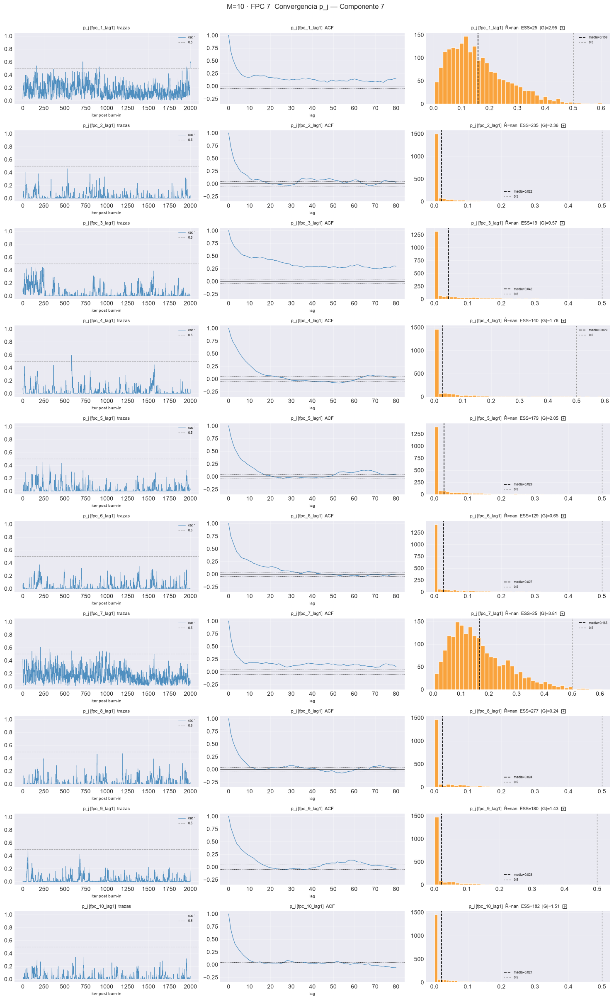

[plot_convergence_bj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.1s eta=0.5s  fpc_1_lag1  rhat=nan  ess_min=52  |G|=5.15  ✗


  2/10 (20.0%) t=0.1s eta=0.4s  fpc_2_lag1  rhat=nan  ess_min=1181  |G|=0.94  ✓


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=24  |G|=1.22  ✗


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=507  |G|=1.44  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=1586  |G|=1.50  ✓


  6/10 (60.0%) t=0.2s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=1604  |G|=0.71  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=45  |G|=0.45  ✗


  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.18  ✓


  9/10 (90.0%) t=0.8s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=1697  |G|=0.33  ✓


  10/10 (100.0%) t=0.8s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=0.34  ✓


[plot_convergence_bj[FPC 8]] listo: 10 pasos en 6.1s  3/10 sin converger


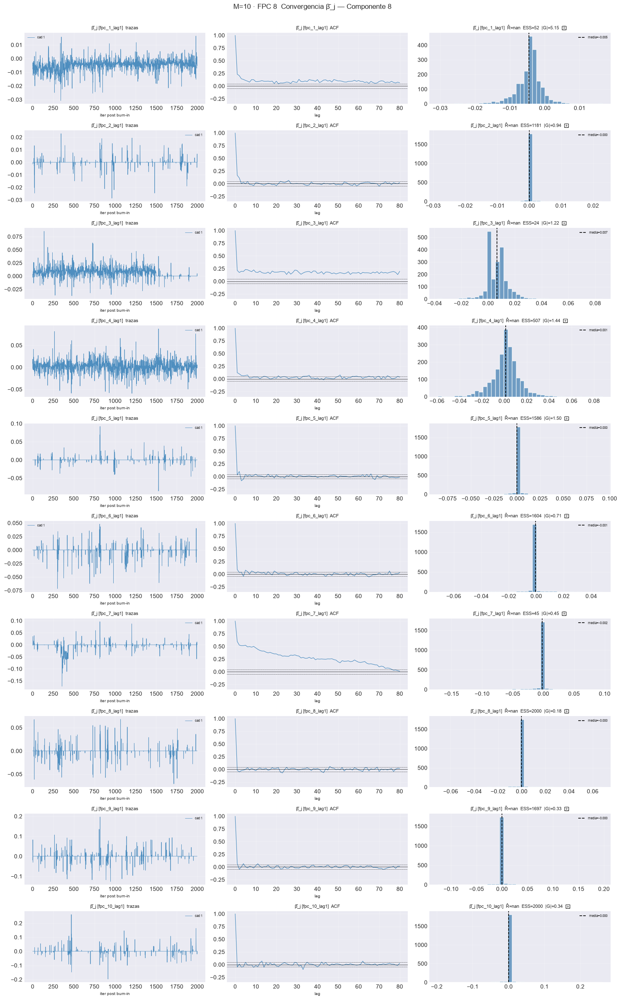

[plot_convergence_pj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.4s  fpc_1_lag1  rhat=nan  ess_min=36  |G|=2.81  ✗


  2/10 (20.0%) t=0.1s eta=0.4s  fpc_2_lag1  rhat=nan  ess_min=312  |G|=0.97  ✓


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=13  |G|=1.62  ✗


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=103  |G|=0.54  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=289  |G|=0.60  ✓


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=241  |G|=0.96  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=76  |G|=0.38  ✗

  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=384  |G|=1.56  ✓


  9/10 (90.0%) t=0.4s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=317  |G|=0.39  ✓


  10/10 (100.0%) t=0.4s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=297  |G|=0.32  ✓

[plot_convergence_pj[FPC 8]] listo: 10 pasos en 5.7s  3/10 sin converger


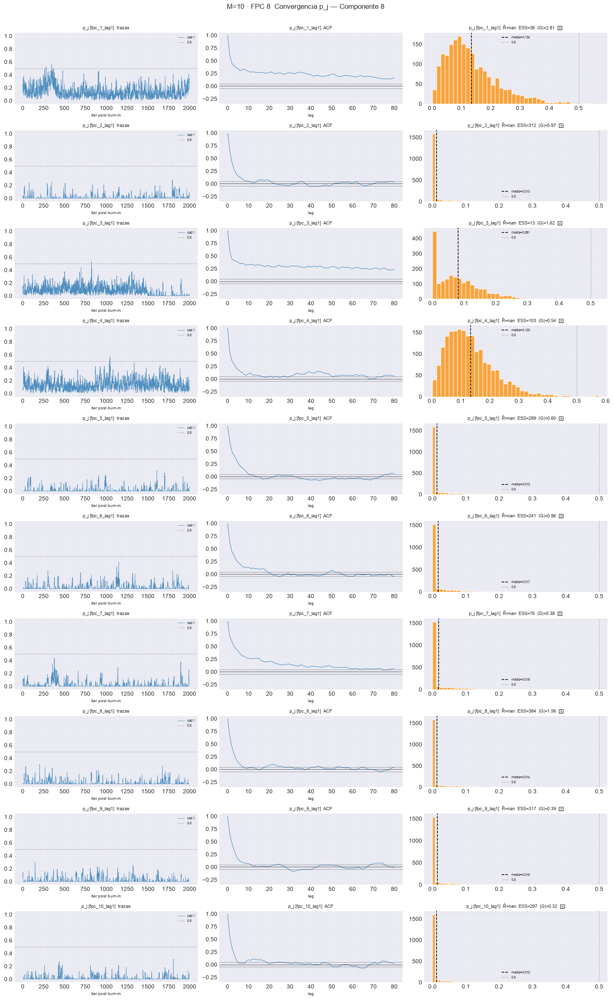

[plot_convergence_bj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1672  |G|=1.31  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1264  |G|=0.33  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=42  |G|=0.43  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1554  |G|=2.26  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=130  |G|=0.56  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=480  |G|=1.33  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1316  |G|=1.53  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1843  |G|=0.52  ✓


  9/10 (90.0%) t=0.5s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=2.76  ✗


  10/10 (100.0%) t=0.6s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1381  |G|=0.87  ✓


[plot_convergence_bj[FPC 9]] listo: 10 pasos en 3.8s  3/10 sin converger


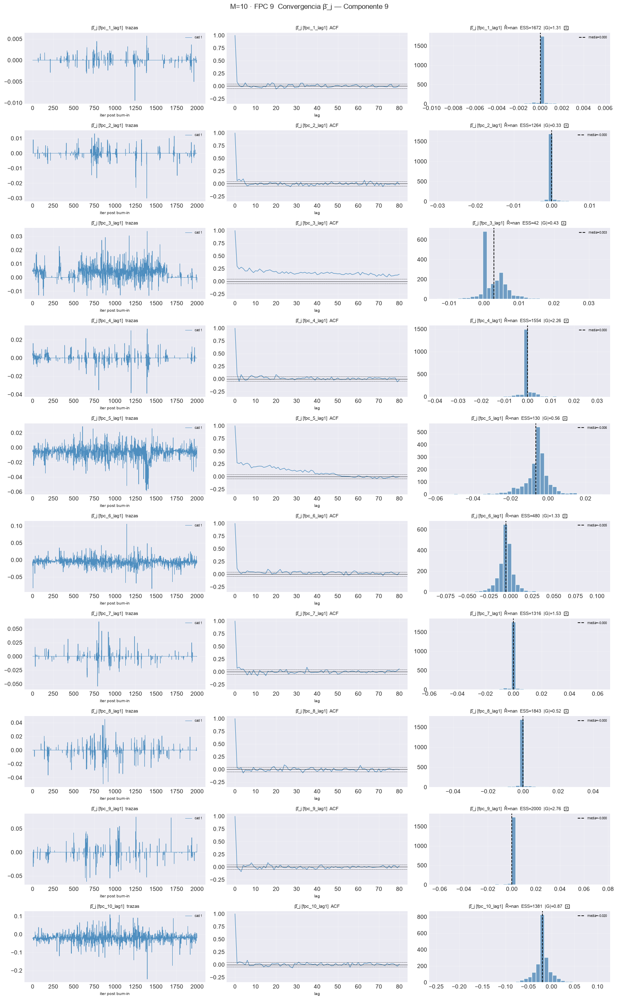

[plot_convergence_pj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=248  |G|=2.14  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=70  |G|=0.11  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=14  |G|=0.38  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=140  |G|=3.00  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=96  |G|=1.74  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=114  |G|=1.39  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=174  |G|=0.47  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=154  |G|=0.26  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=193  |G|=0.41  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=64  |G|=1.78  ✗

[plot_convergence_pj[FPC 9]] listo: 10 pasos en 5.0s  6/10 sin converger


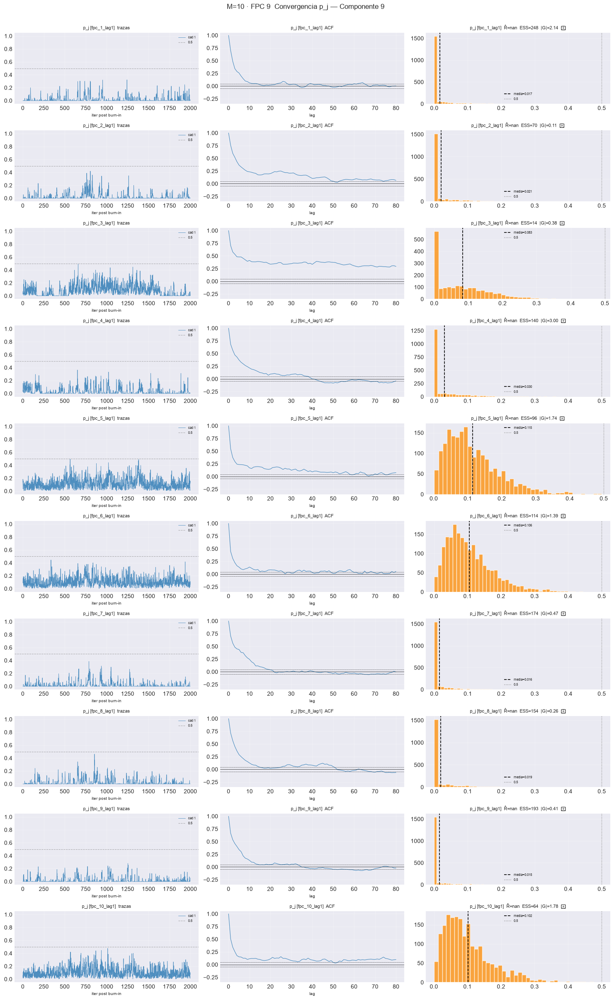

[plot_convergence_bj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.4s  fpc_1_lag1  rhat=nan  ess_min=907  |G|=0.01  ✓


  2/10 (20.0%) t=0.1s eta=0.3s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=0.76  ✓


  3/10 (30.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=nan  ess_min=505  |G|=3.62  ✗


  4/10 (40.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.46  ✓


  5/10 (50.0%) t=0.2s eta=0.2s  fpc_5_lag1  rhat=nan  ess_min=71  |G|=4.86  ✗


  6/10 (60.0%) t=0.2s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1236  |G|=1.40  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=365  |G|=1.14  ✓


  8/10 (80.0%) t=0.3s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=1092  |G|=0.70  ✓


  9/10 (90.0%) t=0.7s eta=0.1s  fpc_9_lag1  rhat=nan  ess_min=889  |G|=0.73  ✓


  10/10 (100.0%) t=0.7s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1737  |G|=2.24  ✗


[plot_convergence_bj[FPC 10]] listo: 10 pasos en 6.1s  3/10 sin converger


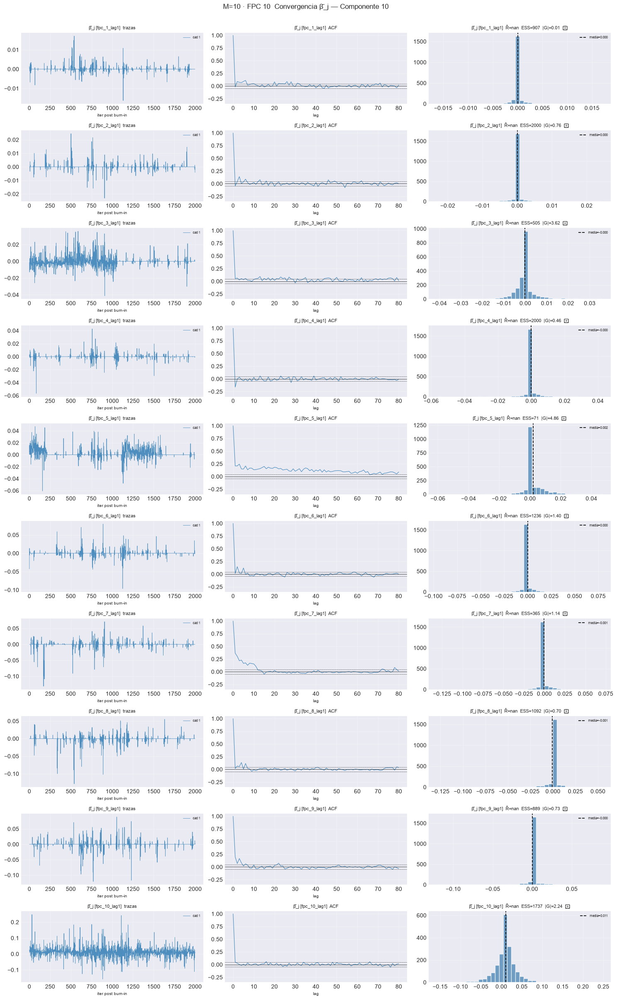

[plot_convergence_pj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.1s eta=0.6s  fpc_1_lag1  rhat=nan  ess_min=146  |G|=1.12  ✓


  2/10 (20.0%) t=0.1s eta=0.4s  fpc_2_lag1  rhat=nan  ess_min=188  |G|=0.44  ✓


  3/10 (30.0%) t=0.2s eta=0.4s  fpc_3_lag1  rhat=nan  ess_min=9  |G|=5.35  ✗


  4/10 (40.0%) t=0.2s eta=0.3s  fpc_4_lag1  rhat=nan  ess_min=90  |G|=0.05  ✗


  5/10 (50.0%) t=0.3s eta=0.3s  fpc_5_lag1  rhat=nan  ess_min=20  |G|=1.34  ✗


  6/10 (60.0%) t=0.3s eta=0.2s  fpc_6_lag1  rhat=nan  ess_min=120  |G|=1.65  ✓


  7/10 (70.0%) t=0.3s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=214  |G|=1.68  ✓


  8/10 (80.0%) t=0.4s eta=0.1s  fpc_8_lag1  rhat=nan  ess_min=169  |G|=0.79  ✓


  9/10 (90.0%) t=0.4s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=83  |G|=0.04  ✗


  10/10 (100.0%) t=0.5s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=64  |G|=3.74  ✗

[plot_convergence_pj[FPC 10]] listo: 10 pasos en 7.0s  5/10 sin converger


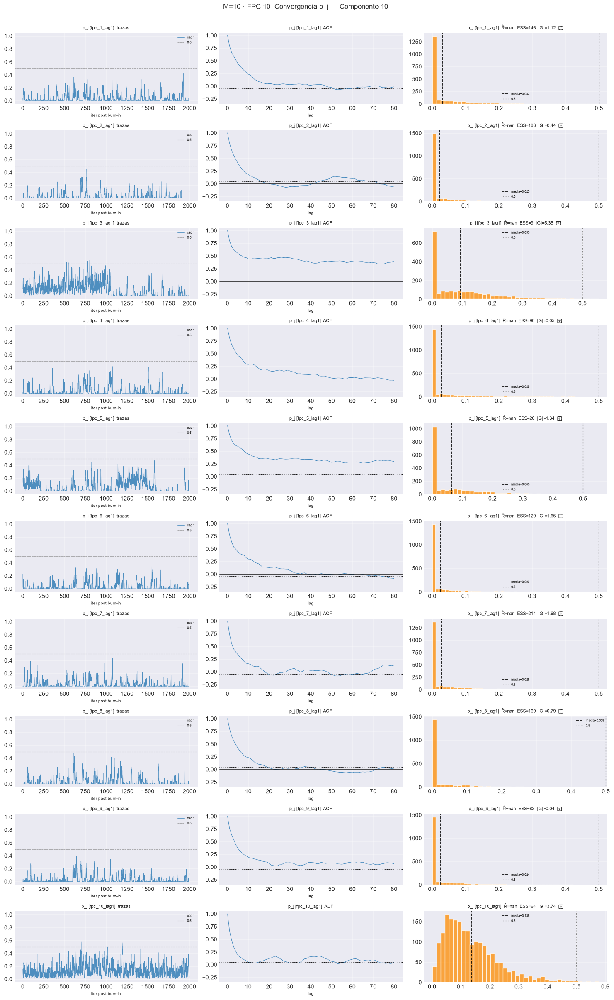

In [9]:
# Traza | ACF | posterior con las métricas anotadas; beta_j va promediado sobre
# átomos (invariante a la permutación de etiquetas). verbose=True saca
# Rhat/ESS/Geweke por covariable a la consola.
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc  = e["component_idx"][k] + 1
        feat = e["models_chains"][k][0].feature_names_
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_convergence_bj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"44_conv_bj_k{fpc}.png"), verbose=True)
        plt.show()
        plot_convergence_pj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"45_conv_pj_k{fpc}.png"), verbose=True)
        plt.show()

## 6. Probabilidades posteriores de inclusión

Tercer eje del diseño (`docs §03_06`): qué variables selecciona el modelo.
Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta
el PIP y su dispersión entre cadenas.

In [10]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} - P(gamma_j = 1 | datos), inclusión global, media entre cadenas +- sd"))

[matriz_pip] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 10 variables, PIP en [0.250, 1.000]


  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 1 cadenas, 10 variables, PIP en [0.268, 1.000]


  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 1 cadenas, 10 variables, PIP en [0.076, 1.000]


  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 1 cadenas, 10 variables, PIP en [0.355, 1.000]


  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 1 cadenas, 10 variables, PIP en [0.176, 1.000]


  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 10 variables, PIP en [0.106, 1.000]


  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 1 cadenas, 10 variables, PIP en [0.100, 1.000]


  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 1 cadenas, 10 variables, PIP en [0.089, 1.000]


  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 1 cadenas, 10 variables, PIP en [0.115, 1.000]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 1 cadenas, 10 variables, PIP en [0.131, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20


[M=10] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,0.150,0.000,0.392,0.000,1.000,0.000,0.998,0.000,1.000,0.000,1.000,0.000,0.133,0.000,0.173,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.512,0.000,0.921,0.000,0.144,0.000,0.100,0.000,0.100,0.000,0.158,0.000,0.131,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.154,0.000,0.237,0.000,0.775,0.000,0.694,0.000,0.586,0.000
fpc_4_lag1,1.000,0.000,0.268,0.000,0.100,0.000,1.000,0.000,0.230,0.000,0.123,0.000,0.130,0.000,1.000,0.000,0.265,0.000,0.151,0.000
fpc_5_lag1,1.000,0.000,1.000,0.000,0.133,0.000,1.000,0.000,1.000,0.000,0.571,0.000,0.136,0.000,0.104,0.000,1.000,0.000,0.404,0.000
fpc_6_lag1,0.410,0.000,1.000,0.000,0.082,0.000,1.000,0.000,0.224,0.000,1.000,0.000,0.139,0.000,0.140,0.000,1.000,0.000,0.142,0.000
fpc_7_lag1,1.000,0.000,1.000,0.000,0.153,0.000,0.968,0.000,0.206,0.000,0.106,0.000,1.000,0.000,0.142,0.000,0.115,0.000,0.161,0.000
fpc_8_lag1,0.250,0.000,0.808,0.000,0.087,0.000,1.000,0.000,0.214,0.000,0.160,0.000,0.113,0.000,0.107,0.000,0.146,0.000,0.152,0.000
fpc_9_lag1,0.276,0.000,0.291,0.000,0.138,0.000,0.383,0.000,0.178,0.000,0.127,0.000,0.118,0.000,0.108,0.000,0.125,0.000,0.138,0.000


## 7. Verificación muestreador ↔ predictor

`inEout` es $E[y\mid x]$ dentro de muestra tal como la calcula MATLAB en cada
iteración. Debe coincidir con lo que el predictor de Python reconstruye de las
mismas trazas: es la única prueba directa de que ambos lados interpretan las
trazas igual. Se corre **en cada $M$** (el contrato depende de $p$).

In [11]:
ok_global = all([verificar_muestreador_predictor(EST[M], CORR_MIN_CONTRATO) for M in M_OK])
print(f"\n{'OK contrato verificado en todo el barrido' if ok_global else 'X el contrato falla'}")

-- M=10 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 3 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 4 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 5 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 6 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 7 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 8 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 9 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 10 cadena1: corr=1.000000  |dif|max=0.0000

OK contrato verificado en todo el barrido


### 7.1 Paso de $\Gamma$: grilla por predictor y normalización

- cada $\Gamma_{hj}$ muestreado cae **en la grilla de su predictor** `Gstar[:, j]`;
- en cada sorteo, `pm1` es finito y suma 1 (`gamdiagout`).

In [12]:
gamma_df = diagnostico_paso_gamma(EST, M_OK)
display(gamma_df[gamma_df.M == max(M_OK)].style
        .format({"dist_max": "{:.1e}", "err_suma_max": "{:.1e}",
                 "rango_log_mediana": "{:.1f}", "rango_log_max": "{:.1f}"})
        .set_caption(f"M={max(M_OK)} - paso de Gamma, post-burn"))

OK Gamma siempre en su grilla y pm1 finita y normalizada   ·   rango_log mediano 1511


,M,FPC,cadena,fuera_de_grilla,dist_max,sorteos,no_finitos,err_suma_max,rango_log_mediana,rango_log_max
0,10,1,1,False,5.9e-08,125398,0,5.6e-16,942.3,3819.6
1,10,2,1,False,5.9e-08,155306,0,5.6e-16,4326.8,24786.5
2,10,3,1,False,5.9e-08,18074,0,4.4e-16,1666.2,7933.8
3,10,4,1,False,5.9e-08,69616,0,4.4e-16,2215.4,7829.1
4,10,5,1,False,5.9e-08,57268,0,5.6e-16,1491.2,6320.2
5,10,6,1,False,5.9e-08,26708,0,4.4e-16,1529.9,9829.8
6,10,7,1,False,5.9e-08,28776,0,4.4e-16,1293.3,18542.5
7,10,8,1,False,5.9e-08,22484,0,4.4e-16,3074.7,14375.8
8,10,9,1,False,5.9e-08,26023,0,5.6e-16,675.4,7545.5
9,10,10,1,False,5.9e-08,24895,0,4.4e-16,442.6,44765.2


## 8. Comparación entre los puntos del barrido

Las cifras son comparables entre $M$: $\hat R$ máx, ESS mín y Geweke máx son el
**peor caso** del punto (no un promedio sobre un número de variables que cambia
con $M$); la ocupación cuenta átomos; el PIP es una proporción en $[0,1]$.

,experiment_id,p_covariables,n_variables_diag,rhat_max,ess_min,geweke_max,n_no_converge,converge,ocupacion_media,ocupacion_max,N_trunc,toca_truncamiento,pip_sd_max,contrato_ok
M,,,,,,,,,,,,,,
10,real_sa1_103_v02_m10,10,200,-,9,12.3225,76,False,18.89,30,30,True,0.0000,True


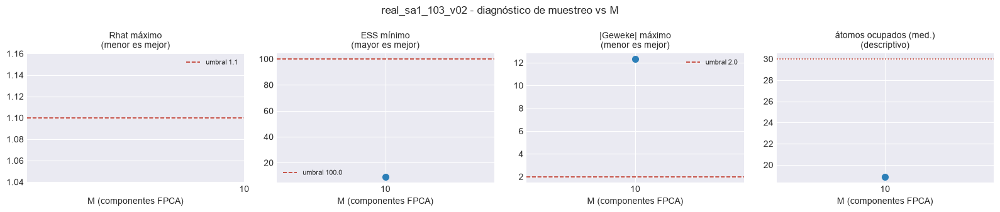

In [13]:
barrido_df = tabla_barrido(EST, M_OK, PATH_BARRIDO)
_fmt = {c: "{:.4f}" for c in ("rhat_max", "geweke_max", "pip_sd_max", "pip_media_activas")
        if c in barrido_df.columns} | {"ess_min": "{:.0f}", "ocupacion_media": "{:.2f}"}
display(barrido_df.style.format(_fmt, na_rep="-")
        .background_gradient(subset=["rhat_max"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption("Diagnóstico de muestreo a lo largo del barrido en M"))

plot_diagnostico_vs_M(barrido_df, EST[M_OK[0]]["res_conv"]["umbrales"], EXPERIMENT_BASE,
                      PATH_BARRIDO / "81_diagnostico_vs_M.png")
plt.show()

FPC,1,2,3,4,5,6,7,8,9,10
M,,,,,,,,,,
10,9.65,11.40,24.27,26.35,15.29,19.32,16.12,24.00,25.35,17.14


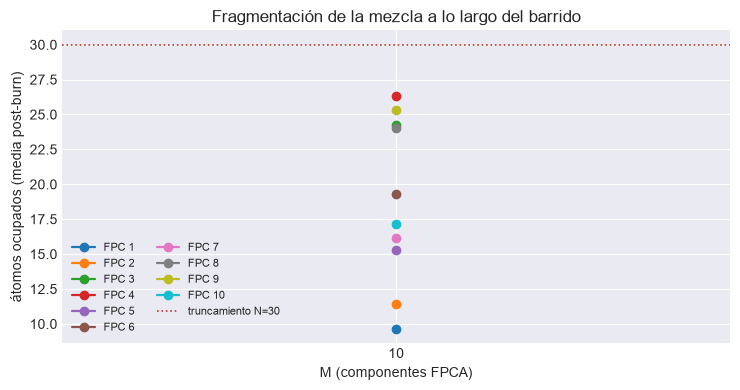

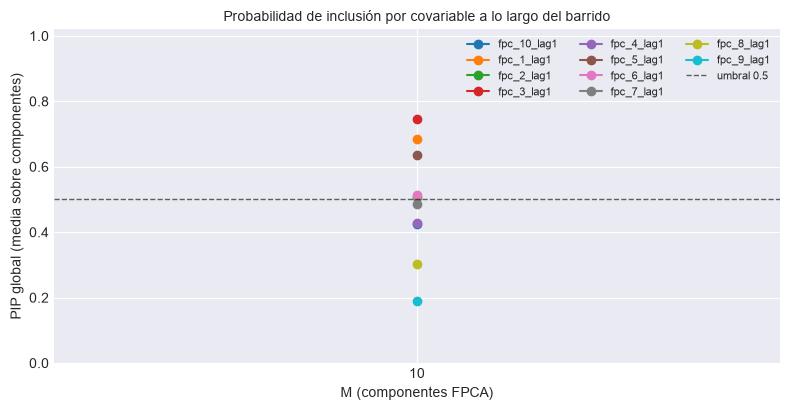

In [14]:
# Ocupación por M y componente: dice si al subir M el modelo parte la mezcla en más átomos.
ocup_todo, piv = ocupacion_barrido(EST, M_OK, PATH_BARRIDO)
display(piv.style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption("Átomos ocupados (media post-burn) por M y componente FPCA"))
plot_ocupacion_vs_M(piv, int(ocup_todo["N_trunc"].iloc[0]), PATH_BARRIDO / "82_ocupacion_por_M.png")
plt.show()

# PIP por covariable a lo largo del barrido (formato largo).
pip_largo = pip_barrido(EST, M_OK, PATH_BARRIDO)
plot_pip_vs_M(pip_largo, M_OK, PATH_BARRIDO / "83_pip_por_M.png")
plt.show()

In [15]:
veredicto_barrido(barrido_df, EXPERIMENT_BASE, M_FPCA_LIST, M_OK, PATH_BARRIDO)
print("Continuar con 103_04_evaluacion, declarando el mismo M_FPCA_LIST.")

  BARRIDO real_sa1_103_v02   ·   M evaluados: [10]
  M=10  p=10  Rhatmax=nan  ESSmin=9  ocup=18.9/30  X NO CONVERGE
------------------------------------------------------------------
X NO convergen: M = [10]. Excluirlos de la comparacion de _04/_05,
  o subir nsim/burn antes de leer su error como efecto de M.
Tablas y figuras cruzadas en C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_barrido_M  (archivos 80-83)
Continuar con 103_04_evaluacion, declarando el mismo M_FPCA_LIST.
